# Money laundering detection on the IBM HI-Small data

Plan: score every transaction, group the flagged ones into cases, and write a short draft SAR (suspicious activity report) for each case.

Models compared: a simple rule engine, XGBoost on per-transaction features, XGBoost with neighbour scores added (a poor man's one-layer GNN), GraphSAGE and GCN.

## Setup

In [1]:
# only needed for the pdf export at the end
%pip install -q reportlab

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import re
import json
import time
import gc
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, confusion_matrix
import xgboost as xgb

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

warnings.filterwarnings("ignore")

In [3]:
SEED = 42
SAMPLE_DAYS = None
SPLIT = (0.60, 0.20, 0.20)

# gnn
HIDDEN = 32
GNN_LAYERS = 2
DROPOUT = 0.2
LR = 3e-3
STEPS = 300
NEG_RATIO = 20
EVAL_EVERY = 10
PATIENCE = 8
RUN_GCN = True
USE_CHECKPOINT = True

# xgboost
XGB_NEG_CAP = 800_000

# evaluation and cases
RECALL_TARGET = 0.80
CTX_TOP_FRAC = 0.005    # extra high scoring edges added around the flagged ones
MAX_CASE_EDGES_LISTED = 40
N_CASES_FOR_SAR = 12

In [4]:
IN_KAGGLE = os.path.exists("/kaggle/input")
IN_COLAB = "google.colab" in sys.modules

if not (IN_KAGGLE or IN_COLAB):
    plt.switch_backend("Agg")

OUT_DIR = "/kaggle/working/outputs" if IN_KAGGLE else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def trim():
    # give freed memory back to the OS (called after big arrays are deleted)
    import ctypes
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.11.0+cpu


## 1. Find the data

In [6]:
def find_file(name):
    roots = ["/kaggle/input", "/kaggle/working", "/content", "/mnt/user-data/uploads", ".",
             os.path.expanduser("~/Downloads")]
    for root in roots:
        if not os.path.isdir(root):
            continue
        for folder, _, files in os.walk(root):
            if name in files:
                return os.path.join(folder, name)
    return None


TRANS_PATH = find_file("HI-Small_Trans.csv")
PATTERNS_PATH = find_file("HI-Small_Patterns.txt")
print(TRANS_PATH)
print(PATTERNS_PATH)

/kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Trans.csv
/kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Patterns.txt


In [7]:
# not found locally, try to pull it from kaggle (needs internet and an api token)
if TRANS_PATH is None or PATTERNS_PATH is None:
    import kagglehub
    folder = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml")
    TRANS_PATH = find_file("HI-Small_Trans.csv")
    PATTERNS_PATH = find_file("HI-Small_Patterns.txt")

assert TRANS_PATH and PATTERNS_PATH, "put HI-Small_Trans.csv and HI-Small_Patterns.txt next to the notebook"

## 2. Load the transactions

The csv is big, so it is read in chunks and stored as compact integers. An account is the bank number and the account number packed into one 64 bit key. Time is kept as minutes since 2022-09-01.

In [8]:
COLS = ["timestamp", "from_bank", "from_acct", "to_bank", "to_acct",
        "amt_recv", "cur_recv", "amt_paid", "cur_paid", "fmt", "y"]
T0 = pd.Timestamp("2022-09-01")

# category -> integer code, filled while reading
cur_map = {}
fmt_map = {}

In [9]:
def code_col(series, mapping):
    # text category to a small integer, the same mapping is reused for every chunk
    for v in series.unique():
        mapping.setdefault(v, len(mapping))
    return series.map(mapping).astype("int16").values


def account_key(bank, acct):
    # bank in the high bits, hex account id in the low 36 bits
    return (bank.astype("int64").values << 36) | acct.map(lambda x: int(x, 16)).astype("int64").values


def parse_rows(chunk):
    minutes = (pd.to_datetime(chunk["timestamp"], format="%Y/%m/%d %H:%M") - T0) // pd.Timedelta(minutes=1)
    return dict(
        ts=minutes.astype("int32").values,
        kS=account_key(chunk["from_bank"], chunk["from_acct"]),
        kD=account_key(chunk["to_bank"], chunk["to_acct"]),
        amt_p=chunk["amt_paid"].astype("float64").values,
        amt_r=chunk["amt_recv"].astype("float64").values,
        cur_p=code_col(chunk["cur_paid"], cur_map),
        cur_r=code_col(chunk["cur_recv"], cur_map),
        fmt=code_col(chunk["fmt"], fmt_map),
        y=chunk["y"].astype("int8").values,
    )

In [10]:
t0 = time.time()
parts = []

for chunk in pd.read_csv(TRANS_PATH, header=0, names=COLS, dtype=str, chunksize=500_000):
    if SAMPLE_DAYS:
        day = chunk["timestamp"].str.slice(0, 10)
        chunk = chunk[(day >= SAMPLE_DAYS[0]) & (day <= SAMPLE_DAYS[1])]
        if chunk.empty:
            continue
    parts.append(pd.DataFrame(parse_rows(chunk)))

df = pd.concat(parts, ignore_index=True)
del parts
print(f"read {len(df):,} rows in {time.time() - t0:.0f}s")

read 5,078,345 rows in 18s


In [11]:
# the file is not sorted by time, so sort it
df = df.sort_values("ts", kind="stable").reset_index(drop=True)
n = len(df)

CUR_NAMES = [k for k, _ in sorted(cur_map.items(), key=lambda kv: kv[1])]
FMT_NAMES = [k for k, _ in sorted(fmt_map.items(), key=lambda kv: kv[1])]

In [12]:
# give every account an integer node id
NODE_KEYS, inv = np.unique(np.concatenate([df.kS.values, df.kD.values]), return_inverse=True)
df["src"] = inv[:n].astype(np.int32)
df["dst"] = inv[n:].astype(np.int32)
del inv
N_NODES = len(NODE_KEYS)


def acct_label(node):
    k = int(NODE_KEYS[node])
    return f"{k >> 36}_{k & ((1 << 36) - 1):09X}"

In [13]:
# time based split
q1 = np.quantile(df.ts.values, SPLIT[0])
q2 = np.quantile(df.ts.values, SPLIT[0] + SPLIT[1])
df["split"] = np.where(df.ts <= q1, 0, np.where(df.ts <= q2, 1, 2)).astype("int8")


def ts_str(minutes):
    return str(T0 + pd.Timedelta(minutes=int(minutes)))

In [14]:
print(f"transactions {n:,} | accounts {N_NODES:,} | illicit {int(df.y.sum()):,} ({100 * df.y.mean():.3f}%)")
print("period:", ts_str(df.ts.min()), "->", ts_str(df.ts.max()))

summary = df.groupby("split").agg(transactions=("y", "size"), illicit=("y", "sum"), rate=("y", "mean"),
                                  first=("ts", "min"), last=("ts", "max"))
summary["first"] = summary["first"].map(ts_str)
summary["last"] = summary["last"].map(ts_str)
print(summary)

transactions 5,078,345 | accounts 515,088 | illicit 5,177 (0.102%)
period: 2022-09-01 00:00:00 -> 2022-09-18 16:18:00
       transactions  illicit      rate                first  \
split                                                         
0           3047216     2299  0.000754  2022-09-01 00:00:00   
1           1015565     1081  0.001064  2022-09-06 13:37:00   
2           1015564     1797  0.001769  2022-09-08 16:13:00   

                      last  
split                       
0      2022-09-06 13:36:00  
1      2022-09-08 16:12:00  
2      2022-09-18 16:18:00  


## 3. Quick look at the data

In [15]:
fmt_names = np.array(FMT_NAMES)
cur_names = np.array(CUR_NAMES)

by_fmt = df.groupby("fmt").y.agg(["mean", "sum", "size"])
by_fmt.index = fmt_names[by_fmt.index]
print(by_fmt.sort_values("mean", ascending=False))

print("self transfers:", int((df.src == df.dst).sum()))
print("cross currency:", int((df.cur_p != df.cur_r).sum()))

                  mean   sum     size
ACH           0.007462  4483   600797
Bitcoin       0.000383    56   146091
Cash          0.000220   108   490891
Cheque        0.000174   324  1864331
Credit Card   0.000156   206  1323324
Reinvestment  0.000000     0   481056
Wire          0.000000     0   171855
self transfers: 591212
cross currency: 72170


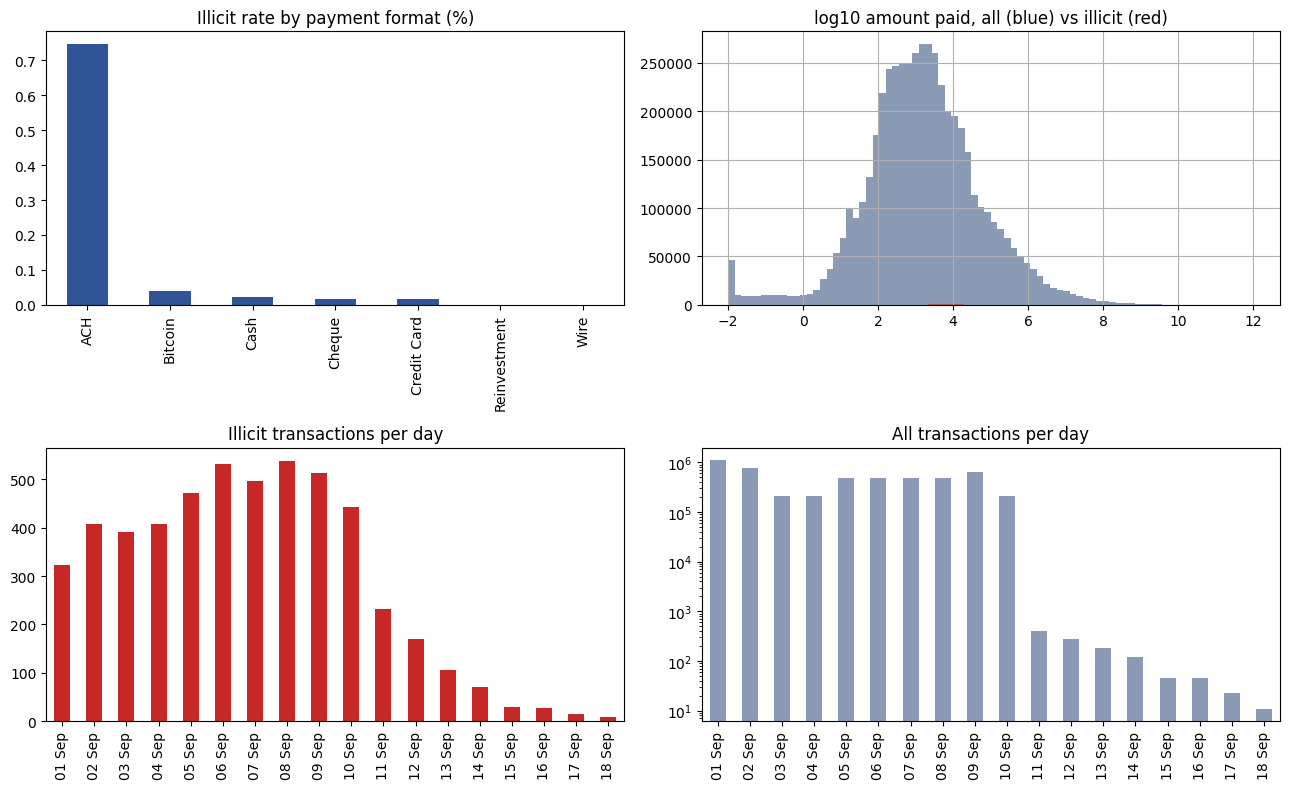

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

(by_fmt["mean"] * 100).sort_values(ascending=False).plot.bar(ax=ax[0, 0], color="#2F5597")
ax[0, 0].set_title("Illicit rate by payment format (%)")

log_amt = np.log10(df.amt_p.clip(lower=0.01))
log_amt.hist(bins=80, ax=ax[0, 1], color="#8C9BB5")
log_amt[df.y == 1].hist(bins=80, ax=ax[0, 1], color="#C62828", alpha=0.6)
ax[0, 1].set_title("log10 amount paid, all (blue) vs illicit (red)")

per_day = df.groupby(df.ts // 1440).y.agg(["sum", "size"])
per_day.index = [(T0 + pd.Timedelta(days=int(i))).strftime("%d %b") for i in per_day.index]

per_day["sum"].plot.bar(ax=ax[1, 0], color="#C62828")
ax[1, 0].set_title("Illicit transactions per day")

per_day["size"].plot.bar(ax=ax[1, 1], color="#8C9BB5")
ax[1, 1].set_title("All transactions per day")
ax[1, 1].set_yscale("log")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/eda.png", dpi=110)
plt.show()

After about 10 Sep almost no normal traffic is left, so the end of the test period is a small tail that is mostly illicit. Keep that in mind when reading the test scores.

## 4. Laundering rings from the patterns file

Every block in `HI-Small_Patterns.txt` is one laundering scheme with a type. The rows are matched back to the transaction table so we can check ring detection and pattern tags later.

In [17]:
def parse_patterns(path):
    rows = []
    pid = -1
    ptype = None
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line.startswith("BEGIN LAUNDERING ATTEMPT"):
                pid += 1
                ptype = re.search(r"ATTEMPT - ([A-Z\-]+)", line).group(1)
            elif line.startswith("END LAUNDERING ATTEMPT"):
                ptype = None
            elif line and ptype:
                rows.append([pid, ptype] + line.split(","))

    p = pd.DataFrame(rows, columns=["pattern_id", "pattern_type"] + COLS)
    meta = p[["pattern_id", "pattern_type"]].reset_index(drop=True)
    return pd.concat([meta, pd.DataFrame(parse_rows(p[COLS]))], axis=1)

In [18]:
pat = parse_patterns(PATTERNS_PATH)
PTYPES = sorted(pat.pattern_type.unique())

print("pattern rows:", len(pat), "| rings:", pat.pattern_id.nunique())
print(pat.groupby("pattern_type").pattern_id.nunique().rename("rings").to_string())

pattern rows: 3209 | rings: 370
pattern_type
BIPARTITE         49
CYCLE             54
FAN-IN            40
FAN-OUT           48
GATHER-SCATTER    51
RANDOM            41
SCATTER-GATHER    44
STACK             43


In [19]:
# match ring rows to transactions on time, accounts, amount (in cents), currency and format
KEYCOLS = ["ts", "kS", "kD", "cents", "cur_p", "fmt"]

pat["cents"] = np.round(pat.amt_p * 100).astype("int64")

illicit = df.loc[df.y == 1, ["ts", "kS", "kD", "amt_p", "cur_p", "fmt"]].copy()
illicit["cents"] = np.round(illicit.amt_p * 100).astype("int64")
illicit["txn_id"] = illicit.index.values

# identical rows can repeat, so number them to keep the merge one to one
illicit["dup"] = illicit.groupby(KEYCOLS).cumcount()
pat["dup"] = pat.groupby(KEYCOLS).cumcount()

link = pat[KEYCOLS + ["dup", "pattern_id", "pattern_type"]].merge(
    illicit[KEYCOLS + ["dup", "txn_id"]], on=KEYCOLS + ["dup"], how="inner")

In [20]:
df["pattern_id"] = np.int32(-1)
df["ptype"] = np.int8(-1)

type_id = {p: i for i, p in enumerate(PTYPES)}
df.loc[link.txn_id.values, "pattern_id"] = link.pattern_id.values.astype(np.int32)
df.loc[link.txn_id.values, "ptype"] = link.pattern_type.map(type_id).values.astype(np.int8)

print(f"ring rows matched to transactions: {len(link):,} / {len(pat):,}")
print("illicit transactions inside a listed ring:", int((df.y.eq(1) & df.pattern_id.ge(0)).sum()), "of", int(df.y.sum()))
del illicit, link

ring rows matched to transactions: 3,209 / 3,209
illicit transactions inside a listed ring: 3209 of 5177


## 5. Edge features

All features are causal: for a transaction they only use what happened before it. For sender and receiver we count transfers and sum money in the last hour, the last 24 hours and the full earlier history. We also keep the time and size of the last incoming transfer (money that leaves right after it arrives is a classic layering sign) and the account age. Amount, currency, format, hour of day and cross bank flags are added on top.

Everything is standardised with train statistics and stored as float16 to save memory.

In [21]:
t0 = time.time()

SPL = df.split.values
TR = SPL == 0                          # training rows
ts = df.ts.values.astype(np.int64)
S = df.src.values.astype(np.int64)
D = df.dst.values.astype(np.int64)
AP = df.amt_p.values
AR = df.amt_r.values
Y = df.y.values.astype(np.float32)
TT = int(ts.max()) + 2                 # keys below are account * TT + time

In [22]:
# 20 windowed + 9 account level + 7 transaction level + one-hot format and currency
n_cols = 20 + 9 + 7 + len(FMT_NAMES) + len(CUR_NAMES)

E16 = np.zeros((n, n_cols), dtype=np.float16)
E_NAMES, E_MU, E_SD = [], [], []


def put(name, values):
    # standardise with train statistics, clip outliers, store as float16
    a = np.asarray(values, dtype=np.float32)
    mu = float(a[TR].mean())
    sd = float(a[TR].std()) + 1e-6
    E16[:, len(E_NAMES)] = np.clip((a - mu) / sd, -10, 10).astype(np.float16)
    E_NAMES.append(name)
    E_MU.append(mu)
    E_SD.append(sd)

In [23]:
def sorted_events(account, amount):
    # sorting by account * TT + time groups rows by account and keeps them in time order
    key = account * TT + ts
    order = np.argsort(key, kind="stable")
    cum_amount = np.concatenate([[0.0], np.cumsum(amount[order])])
    return key[order], cum_amount, ts[order], amount[order]


EVENTS = {
    "out": sorted_events(S, AP),   # money leaving an account
    "in": sorted_events(D, AR),    # money arriving at an account
}

In [24]:
BIG = 30000.0    # "time since last event" when there is none
sums_24h, sums_all = {}, {}
last_gap, last_amt, first_seen = {}, {}, {}

for role, acct in (("s", S), ("d", D)):
    for kind in ("out", "in"):
        key_sorted, cum, t_sorted, a_sorted = EVENTS[kind]

        # events of this account that happened before the current transaction
        hi = np.searchsorted(key_sorted, acct * TT + ts, side="left")

        for W in (60, 1440, None):
            start = np.maximum(ts - W, 0) if W else 0
            lo = np.searchsorted(key_sorted, acct * TT + start, side="left")
            label = W or "all"

            put(f"{role}_{kind}_cnt_{label}", np.log1p(hi - lo))

            if W != 60:
                total = cum[hi] - cum[lo]
                put(f"{role}_{kind}_sum_{label}", np.log1p(total))
                (sums_24h if W == 1440 else sums_all)[(role, kind)] = total.astype(np.float64)

            if W is None:
                # full history: most recent and oldest earlier event
                has_any = hi > lo
                last = np.where(has_any, hi - 1, 0)
                last_gap[(role, kind)] = np.where(has_any, ts - t_sorted[last], BIG)
                last_amt[(role, kind)] = np.where(has_any, a_sorted[last], 0.0)
                first_seen[(role, kind)] = np.where(has_any, t_sorted[np.where(has_any, lo, 0)], ts)
        del hi, lo

In [25]:
gap_names = {("s", "in"): "s_lastin_gap", ("s", "out"): "s_lastout_gap",
             ("d", "in"): "d_lastin_gap", ("d", "out"): "d_lastout_gap"}
for key, name in gap_names.items():
    put(name, np.log1p(last_gap[key]))

# how big is this payment compared to what just came in
had_incoming = last_gap[("s", "in")] < BIG
ratio = np.where(had_incoming, AP / (last_amt[("s", "in")] + 1e-6), 0)
put("s_lastin_ratio", np.log1p(np.clip(ratio, 0, 1e3)))
put("s_amt_vs_in24", np.log1p(np.clip(AP / (sums_24h[("s", "in")] + 1), 0, 1e3)))
put("s_amt_vs_inall", np.log1p(np.clip(AP / (sums_all[("s", "in")] + 1), 0, 1e3)))

# account age in minutes at the time of the transaction
put("s_age", np.log1p(ts - np.minimum(first_seen[("s", "out")], first_seen[("s", "in")])))
put("d_age", np.log1p(ts - np.minimum(first_seen[("d", "out")], first_seen[("d", "in")])))

del EVENTS, sums_24h, sums_all, last_gap, last_amt, first_seen
gc.collect()

2897

In [26]:
hour = (ts % 1440) / 60.0

put("log_amt_paid", np.log1p(AP))
put("log_amt_recv", np.log1p(AR))
put("cross_currency", df.cur_p.values != df.cur_r.values)
put("cross_bank", (df.kS.values >> 36) != (df.kD.values >> 36))
put("self_transfer", S == D)
put("hour_sin", np.sin(2 * np.pi * hour / 24))
put("hour_cos", np.cos(2 * np.pi * hour / 24))

for i, name in enumerate(FMT_NAMES):
    put(f"fmt_{name}", df.fmt.values == i)
for i, name in enumerate(CUR_NAMES):
    put(f"cur_{name}", df.cur_p.values == i)

assert len(E_NAMES) == n_cols, (len(E_NAMES), n_cols)
E_MU = np.array(E_MU, dtype=np.float64)
E_SD = np.array(E_SD, dtype=np.float64)
print(f"edge features: {n_cols} columns x {n:,} rows ({E16.nbytes / 1e6:.0f} MB) in {time.time() - t0:.0f}s")

edge features: 58 columns x 5,078,345 rows (589 MB) in 68s


## 6. Graph views for the GNNs

Node features come from the edges the model is allowed to see at that point in time. The train view only has the training period, the validation view has train and validation, and the test view has everything. Each node gets degree, amount, counterparty and cross bank / currency stats, standardised with train numbers.

Views are built when needed and dropped afterwards, they are big.

In [27]:
LOGP = np.log1p(AP).astype(np.float32)
XBANK = ((df.kS.values >> 36) != (df.kD.values >> 36)).astype(np.float32)
CURMIS = (df.cur_p.values != df.cur_r.values).astype(np.float32)


def raw_node_feats(mask):
    # per account stats from the edges selected by mask
    s, d = S[mask], D[mask]
    amt, logp, xb, cm = AP[mask], LOGP[mask], XBANK[mask], CURMIS[mask]
    N = N_NODES

    out_deg = np.bincount(s, minlength=N).astype(np.float32)
    in_deg = np.bincount(d, minlength=N).astype(np.float32)
    sent = np.bincount(s, weights=amt, minlength=N)
    received = np.bincount(d, weights=amt, minlength=N)

    def mean_over(group, weights, count):
        return np.bincount(group, weights=weights, minlength=N) / np.maximum(count, 1)

    # distinct counterparties
    pairs = np.unique(s * N + d)
    uniq_out = np.bincount(pairs // N, minlength=N)
    uniq_in = np.bincount(pairs % N, minlength=N)

    cols = [
        np.log1p(out_deg), np.log1p(in_deg),
        np.log1p(sent), np.log1p(received),
        mean_over(s, logp, out_deg), mean_over(d, logp, in_deg),
        mean_over(s, xb, out_deg), mean_over(d, xb, in_deg),
        np.log1p(uniq_out), np.log1p(uniq_in),
        mean_over(s, cm, out_deg), mean_over(d, cm, in_deg),
        np.log1p(np.minimum(sent / (received + 1.0), 1e3)),
    ]
    return np.column_stack(cols).astype(np.float32)

In [28]:
nf_train = raw_node_feats(SPL == 0)
active = (nf_train[:, 0] + nf_train[:, 1]) > 0    # accounts seen in training
nf_mu = nf_train[active].mean(0)
nf_sd = nf_train[active].std(0) + 1e-6
NODE_FEATS = nf_train.shape[1]
del nf_train

In [29]:
def to_torch_csr(A):
    A = A.tocsr()
    A.sort_indices()
    return torch.sparse_csr_tensor(
        torch.from_numpy(A.indptr.astype(np.int64)),
        torch.from_numpy(A.indices.astype(np.int64)),
        torch.from_numpy(A.data.astype(np.float32)),
        size=A.shape).to(DEVICE)


def norm_adj(rows, cols):
    # row normalised adjacency, so a matrix product is a mean over neighbours
    deg = np.bincount(rows, minlength=N_NODES).astype(np.float32)
    w = (1.0 / np.maximum(deg[rows], 1)).astype(np.float32)
    return to_torch_csr(sp.coo_matrix((w, (rows, cols)), shape=(N_NODES, N_NODES)))


def gcn_adj(s, d):
    # D^-1/2 (A + A^T + I) D^-1/2
    A = sp.coo_matrix((np.ones(len(s), np.float32), (s, d)), shape=(N_NODES, N_NODES)).tocsr()
    A = A + A.T
    A.data[:] = 1.0
    A = A + sp.eye(N_NODES, dtype=np.float32, format="csr")
    dinv = 1.0 / np.sqrt(np.asarray(A.sum(1)).ravel())
    return to_torch_csr(sp.diags(dinv) @ A @ sp.diags(dinv))

In [30]:
class View:
    # everything a GNN needs to know about the graph at one point in time
    pass


def make_view(mask):
    v = View()
    s, d = S[mask], D[mask]
    x = (raw_node_feats(mask) - nf_mu) / nf_sd
    v.x = torch.from_numpy(x.astype(np.float32)).to(DEVICE)
    v.A_in = norm_adj(d, s)      # mean over senders
    v.A_out = norm_adj(s, d)     # mean over receivers
    v.A_gcn = gcn_adj(s, d) if RUN_GCN else None
    return v


VIEW_MASKS = {"train": SPL == 0, "val": SPL <= 1, "test": SPL <= 2}
_views = {}


def get_view(name):
    if name not in _views:
        _views[name] = make_view(VIEW_MASKS[name])
    return _views[name]


def drop_view(name):
    _views.pop(name, None)
    gc.collect()

In [31]:
# not needed any more, free the memory
for c in ("kS", "kD", "amt_r", "cur_r"):
    del df[c]
del AR
trim()

IDX = {k: np.where(SPL == k)[0] for k in (0, 1, 2)}

E_t = torch.from_numpy(E16).to(DEVICE)
S_t = torch.from_numpy(S).to(DEVICE)
D_t = torch.from_numpy(D).to(DEVICE)
Y_t = torch.from_numpy(Y).to(DEVICE)

print({k: (len(v), int(Y[v].sum())) for k, v in IDX.items()}, "(transactions, illicit) per split")

{0: (3047216, 2299), 1: (1015565, 1081), 2: (1015564, 1797)} (transactions, illicit) per split


## 7. Evaluation helpers

Thresholds are always picked on the validation period and then used unchanged on the test period.

In [32]:
def thr_best_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    return float(t[np.nanargmax(f1[:-1])])


def thr_for_recall(y, s, target=RECALL_TARGET):
    # highest threshold that still reaches the target recall
    p, r, t = precision_recall_curve(y, s)
    ok = np.where(r[:-1] >= target)[0]
    return float(t[ok.max()]) if len(ok) else float(t[0])


def confusion_metrics(y, s, thr):
    pred = s >= thr
    tp = int((pred & (y == 1)).sum())
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    tn = int((~pred & (y == 0)).sum())

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)
    return dict(
        accuracy=(tp + tn) / len(y),
        balanced_accuracy=(recall + specificity) / 2,
        precision=precision,
        recall=recall,
        specificity=specificity,
        f1=2 * precision * recall / max(precision + recall, 1e-12),
        alerts=tp + fp,
        alert_rate=(tp + fp) / len(y),
        tp=tp, fp=fp, fn=fn, tn=tn,
    )

In [33]:
RESULTS, SCORES, THRESH = {}, {}, {}

# transactions from 11 Sep on, the illicit heavy tail of the test period
TAIL = df.ts.values[IDX[2]] >= 10 * 1440


def record(name, s_val, s_test, thr_f1=None, thr_r80=None):
    yv, yt = Y[IDX[1]], Y[IDX[2]]
    if thr_f1 is None:
        thr_f1 = thr_best_f1(yv, s_val)
        thr_r80 = thr_for_recall(yv, s_val)

    r = dict(
        model=name,
        val_pr_auc=average_precision_score(yv, s_val),
        test_pr_auc=average_precision_score(yt, s_test),
        test_roc_auc=roc_auc_score(yt, s_test),
        thr_f1=thr_f1,
        thr_recall80=thr_r80,
    )
    r.update({"f1op_" + k: v for k, v in confusion_metrics(yt, s_test, thr_f1).items()})
    r.update({"r80op_" + k: v for k, v in confusion_metrics(yt, s_test, thr_r80).items()})

    # same thing without the illicit heavy tail
    main = ~TAIL
    if main.sum() and yt[main].sum() and yt[main].sum() < main.sum():
        m = confusion_metrics(yt[main], s_test[main], thr_f1)
        r["test_pr_auc_before_tail"] = average_precision_score(yt[main], s_test[main])
        r["f1op_recall_before_tail"] = m["recall"]
        r["f1op_precision_before_tail"] = m["precision"]

    RESULTS[name] = r
    SCORES[name] = (s_val, s_test)
    THRESH[name] = dict(f1=thr_f1, r80=thr_r80)

    print(f"{name:10s} val PR-AUC {r['val_pr_auc']:.3f} | test PR-AUC {r['test_pr_auc']:.3f}, ROC-AUC {r['test_roc_auc']:.4f}")
    print(f"{'':10s} best-F1:  P {r['f1op_precision']:.3f}  R {r['f1op_recall']:.3f}  F1 {r['f1op_f1']:.3f}  acc {r['f1op_accuracy']:.4f}")
    print(f"{'':10s} R>=80%:   R {r['r80op_recall']:.3f}  P {r['r80op_precision']:.3f}  bal-acc {r['r80op_balanced_accuracy']:.3f}")

## 8. Baselines

First a rule engine: flag a transaction if the amount is very large, or if the sender or receiver had many transfers in the last 24 hours. The two limits are picked by a small grid search on the training period.

Then XGBoost on the edge features. Both use the same split.

In [34]:
col = {name: i for i, name in enumerate(E_NAMES)}


def raw_col(name, idx):
    # undo the standardisation to get the real value back
    return E16[idx, col[name]].astype(np.float32) * E_SD[col[name]] + E_MU[col[name]]


def rule_pred(idx, amount_limit, k):
    big = AP[idx] >= amount_limit
    busy_sender = np.expm1(raw_col("s_out_cnt_1440", idx)) >= k
    busy_receiver = np.expm1(raw_col("d_in_cnt_1440", idx)) >= k
    return (big | busy_sender | busy_receiver).astype(np.float32)

In [35]:
y_train = Y[IDX[0]]
best_f1, best_rule = -1, None

for q in (0.95, 0.99, 0.995, 0.999, 0.9999):
    limit = np.quantile(AP[IDX[0]], q)
    for k in (3, 5, 10, 20, 50):
        pred = rule_pred(IDX[0], limit, k)
        tp = ((pred == 1) & (y_train == 1)).sum()
        precision = tp / max(pred.sum(), 1)
        recall = tp / max(y_train.sum(), 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-12)
        if f1 > best_f1:
            best_f1, best_rule = f1, (limit, k, q)

A_best, K_best, q_best = best_rule
print(f"best rule on train: amount >= {A_best:,.0f} (q={q_best}) or >= {K_best} transfers in 24h | train F1 {best_f1:.4f}")

best rule on train: amount >= 6,416,622,045 (q=0.9999) or >= 50 transfers in 24h | train F1 0.0029


In [36]:
rule_val = rule_pred(IDX[1], A_best, K_best)
rule_test = rule_pred(IDX[2], A_best, K_best)
record("rule", rule_val, rule_test, thr_f1=0.5, thr_r80=0.5)
print("alerts on test:", int(RESULTS["rule"]["f1op_alerts"]))

rule       val PR-AUC 0.001 | test PR-AUC 0.002, ROC-AUC 0.4878
           best-F1:  P 0.001  R 0.072  F1 0.003  acc 0.9023
           R>=80%:   R 0.072  P 0.001  bal-acc 0.488
alerts on test: 97666


In [37]:
def xgb_predict(model, idx, size=250_000):
    # predict in chunks, the float32 copy of all features would not fit in memory
    out = [model.predict_proba(E16[idx[i:i + size]].astype(np.float32))[:, 1] for i in range(0, len(idx), size)]
    return np.concatenate(out)

In [38]:
rng = np.random.default_rng(SEED)

# train on all positives and a capped sample of negatives
pos = IDX[0][Y[IDX[0]] == 1]
neg_all = IDX[0][Y[IDX[0]] == 0]
neg = neg_all if len(neg_all) <= XGB_NEG_CAP else rng.choice(neg_all, XGB_NEG_CAP, replace=False)

fit_idx = np.concatenate([pos, neg])
X_fit, y_fit = E16[fit_idx].astype(np.float32), Y[fit_idx]

# validation subsample for early stopping: all positives, up to 300k negatives
val_pos = IDX[1][Y[IDX[1]] == 1]
val_neg = IDX[1][Y[IDX[1]] == 0]
val_neg = rng.choice(val_neg, min(len(val_neg), 300_000), replace=False)
v_idx = np.concatenate([val_pos, val_neg])
X_v, y_v = E16[v_idx].astype(np.float32), Y[v_idx]

In [39]:
def fit_xgb(**kw):
    model = xgb.XGBClassifier(
        n_estimators=600, learning_rate=0.06, subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", eval_metric="aucpr", early_stopping_rounds=40,
        n_jobs=-1, random_state=SEED, device="cuda" if torch.cuda.is_available() else "cpu", **kw)
    model.fit(X_fit, y_fit, eval_set=[(X_v, y_v)], verbose=False)
    return model


t0 = time.time()
trials = {}
for depth, spw in ((6, 5), (8, 20)):
    m = fit_xgb(max_depth=depth, scale_pos_weight=spw, min_child_weight=2)
    trials[(depth, spw)] = (m.best_score, m)
    print(f"depth {depth}, scale_pos_weight {spw}: val AUCPR {m.best_score:.4f} at {m.best_iteration} trees ({time.time() - t0:.0f}s)")

xgb_model = max(trials.values(), key=lambda t: t[0])[1]

depth 6, scale_pos_weight 5: val AUCPR 0.5362 at 473 trees (46s)
depth 8, scale_pos_weight 20: val AUCPR 0.5066 at 284 trees (79s)


In [40]:
record("xgboost", xgb_predict(xgb_model, IDX[1]), xgb_predict(xgb_model, IDX[2]))
del X_fit, X_v, trials
trim()

xgboost    val PR-AUC 0.361 | test PR-AUC 0.331, ROC-AUC 0.9833
           best-F1:  P 0.416  R 0.338  F1 0.373  acc 0.9980
           R>=80%:   R 0.846  P 0.050  bal-acc 0.909


### XGBoost plus neighbour scores

One transfer on its own often looks normal, a ring is a group of linked transfers. So stage 2 gives XGBoost the stage 1 risk scores of the other transactions that touch the same sender and receiver (previous and next hour, 24 hours, whole period): the mean score, the number of high scoring neighbours, and the transaction's own stage 1 score.

For training rows the stage 1 scores are out-of-fold (3 time blocks), otherwise the model would see scores fitted on its own labels. It works like one message passing layer of a GNN, with learned scores as the messages.

In [41]:
t0 = time.time()

# keep the stage 1 settings, but no early stopping and a fixed number of trees
XGB_PARAMS = xgb_model.get_params()
XGB_PARAMS.update(early_stopping_rounds=None, n_estimators=int(xgb_model.best_iteration) + 1)

tr_idx = IDX[0]
blocks = np.array_split(np.arange(len(tr_idx)), 3)

# stage 1 scores for every row: val and test from the model above, train out-of-fold
P1 = np.zeros(n, np.float32)
P1[IDX[1]] = SCORES["xgboost"][0]
P1[IDX[2]] = SCORES["xgboost"][1]

rng2 = np.random.default_rng(SEED + 1)
for k, blk in enumerate(blocks):
    held = tr_idx[blk]
    fit = np.concatenate([tr_idx[b] for j, b in enumerate(blocks) if j != k])

    fit_pos = fit[Y[fit] == 1]
    fit_neg = fit[Y[fit] == 0]
    fit_neg = rng2.choice(fit_neg, min(len(fit_neg), int(XGB_NEG_CAP * 0.7)), replace=False)
    fi = np.concatenate([fit_pos, fit_neg])

    m_ = xgb.XGBClassifier(**XGB_PARAMS)
    m_.fit(E16[fi].astype(np.float32), Y[fi], verbose=False)
    P1[held] = xgb_predict(m_, held)
    del m_, fi, fit_pos, fit_neg, fit
    trim()
    print(f"out-of-fold block {k}: AP {average_precision_score(Y[held], P1[held]):.3f} ({time.time() - t0:.0f}s)")

out-of-fold block 0: AP 0.020 (23s)
out-of-fold block 1: AP 0.096 (46s)
out-of-fold block 2: AP 0.240 (68s)


In [42]:
def neighbour_features(P):
    # P is the stage 1 score of every transaction
    global NB_HIGH_CUT
    high_cut = float(np.quantile(P[TR], 0.999))
    NB_HIGH_CUT = high_cut    # saved in the bundle, the service must use the same cut-off
    is_high = (P >= high_cut).astype(np.float32)

    # every transaction is listed twice, under its sender and under its receiver
    keys = np.concatenate([S * TT + ts, D * TT + ts])
    order = np.argsort(keys, kind="stable")
    keys_sorted = keys[order]
    del keys
    trim()

    both = np.empty(2 * n, dtype=np.float64)
    both[:n] = P
    both[n:] = P
    cum_p = np.zeros(2 * n + 1)
    np.cumsum(both[order], out=cum_p[1:])

    both32 = np.empty(2 * n, dtype=np.float32)
    both32[:n] = is_high
    both32[n:] = is_high
    cum_h = np.zeros(2 * n + 1, dtype=np.float32)
    np.cumsum(both32[order], out=cum_h[1:])
    del order, both, both32
    trim()

    # a self transfer shows up twice under the same account, take both out
    self_mult = 1 + (S == D).astype(np.int64)
    cols, names = [], []

    for role, acct in (("s", S), ("d", D)):
        for W in (60, 1440, None):
            start = np.maximum(ts - W, 0) if W else 0
            end = np.minimum(ts + W, TT - 1) if W else TT - 1
            lo = np.searchsorted(keys_sorted, acct * TT + start, side="left")
            hi = np.searchsorted(keys_sorted, acct * TT + end, side="right")

            count = np.maximum(hi - lo - self_mult, 0)
            score_sum = cum_p[hi] - cum_p[lo] - self_mult * P
            n_high = cum_h[hi] - cum_h[lo] - self_mult * is_high

            mean_score = np.maximum(score_sum, 0) / np.maximum(count, 1)
            cols.append(np.log10(mean_score + 1e-6).astype(np.float16))
            cols.append(np.log1p(np.maximum(n_high, 0)).astype(np.float16))
            names += [f"nb_{role}_meanp_{W or 'all'}", f"nb_{role}_highrisk_{W or 'all'}"]
            del lo, hi, count, score_sum, n_high

    # the transaction's own stage 1 score as a logit
    pc = np.clip(P, 1e-6, 1 - 1e-6)
    cols.append(np.log(pc / (1 - pc)).astype(np.float16))
    names.append("stage1_logit")
    del keys_sorted, cum_p, cum_h
    trim()
    return np.column_stack(cols), names


X2, NB_NAMES = neighbour_features(P1)

In [43]:
def stack_x(idx):
    return np.hstack([E16[idx].astype(np.float32), X2[idx].astype(np.float32)])


def stack_predict(model, idx, size=250_000):
    out = [model.predict_proba(stack_x(idx[i:i + size]))[:, 1] for i in range(0, len(idx), size)]
    return np.concatenate(out)

In [44]:
xgb_graph = xgb.XGBClassifier(**xgb_model.get_params())
xgb_graph.fit(stack_x(fit_idx), Y[fit_idx], eval_set=[(stack_x(v_idx), Y[v_idx])], verbose=False)
print(f"stage 2: {xgb_graph.best_iteration + 1} trees, val AUCPR {xgb_graph.best_score:.4f} ({time.time() - t0:.0f}s)")

record("xgb_graph", stack_predict(xgb_graph, IDX[1]), stack_predict(xgb_graph, IDX[2]))
# X2 and P1 are kept for the reload check in section 14

stage 2: 171 trees, val AUCPR 0.7009 (154s)
xgb_graph  val PR-AUC 0.605 | test PR-AUC 0.717, ROC-AUC 0.9898
           best-F1:  P 0.780  R 0.637  F1 0.701  acc 0.9990
           R>=80%:   R 0.872  P 0.099  bal-acc 0.929


## 9. GraphSAGE and GCN

GraphSAGE is written in plain PyTorch with sparse mean aggregation, so the whole 5M edge graph fits. Each layer mixes a node's own state, the mean over its senders and the mean over its receivers, each with its own weights (so messages flow in both directions). The edge score is an MLP on `[h_src, h_dst, h_src * h_dst, edge features]`.

The GCN uses the symmetric normalised adjacency with the same inputs and edge head, as a comparison. Both train on all positives plus a fresh random sample of negatives at every step.

In [45]:
class EdgeHead(nn.Module):
    def __init__(self, hid, edge_in, drop):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(3 * hid + edge_in, 4 * hid), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(4 * hid, 2 * hid), nn.ReLU(),
            nn.Linear(2 * hid, 1))

    def forward(self, h, e, s, d):
        x = torch.cat([h[s], h[d], h[s] * h[d], e], dim=1)
        return self.mlp(x).squeeze(-1)

In [46]:
class SAGEEdgeNet(nn.Module):
    def __init__(self, node_in, edge_in, hid=HIDDEN, layers=GNN_LAYERS, drop=DROPOUT):
        super().__init__()
        self.inp = nn.Linear(node_in, hid)
        self.w_self = nn.ModuleList([nn.Linear(hid, hid) for _ in range(layers)])
        self.w_in = nn.ModuleList([nn.Linear(hid, hid, bias=False) for _ in range(layers)])
        self.w_out = nn.ModuleList([nn.Linear(hid, hid, bias=False) for _ in range(layers)])
        self.norm = nn.ModuleList([nn.LayerNorm(hid) for _ in range(layers)])
        self.drop = nn.Dropout(drop)
        self.head = EdgeHead(hid, edge_in, drop)

    def layer(self, i, h, A_in, A_out):
        from_senders = torch.sparse.mm(A_in, h)
        from_receivers = torch.sparse.mm(A_out, h)
        z = self.w_self[i](h) + self.w_in[i](from_senders) + self.w_out[i](from_receivers)
        return h + self.drop(F.relu(self.norm[i](z)))

    def encode(self, v):
        h = F.relu(self.inp(v.x))
        for i in range(len(self.w_self)):
            if self.training and USE_CHECKPOINT:
                h = checkpoint(self.layer, i, h, v.A_in, v.A_out, use_reentrant=False)
            else:
                h = self.layer(i, h, v.A_in, v.A_out)
        return h

    def logits(self, h, e, s, d):
        return self.head(h, e, s, d)

In [47]:
class GCNEdgeNet(nn.Module):
    # h' = relu(A_hat h W) with a residual connection
    def __init__(self, node_in, edge_in, hid=HIDDEN, layers=GNN_LAYERS, drop=DROPOUT):
        super().__init__()
        self.inp = nn.Linear(node_in, hid)
        self.ws = nn.ModuleList([nn.Linear(hid, hid) for _ in range(layers)])
        self.drop = nn.Dropout(drop)
        self.head = EdgeHead(hid, edge_in, drop)

    def layer(self, i, h, A):
        return h + self.drop(F.relu(self.ws[i](torch.sparse.mm(A, h))))

    def encode(self, v):
        h = F.relu(self.inp(v.x))
        for i in range(len(self.ws)):
            if self.training and USE_CHECKPOINT:
                h = checkpoint(self.layer, i, h, v.A_gcn, use_reentrant=False)
            else:
                h = self.layer(i, h, v.A_gcn)
        return h

    def logits(self, h, e, s, d):
        return self.head(h, e, s, d)

In [48]:
@torch.no_grad()
def predict(model, view, idx, chunk=150_000):
    model.eval()
    h = model.encode(view)
    out = []
    for i in range(0, len(idx), chunk):
        j = torch.from_numpy(idx[i:i + chunk]).to(DEVICE)
        logit = model.logits(h, E_t[j].float(), S_t[j], D_t[j])
        out.append(torch.sigmoid(logit).cpu().numpy())
    return np.concatenate(out)

In [49]:
def train_gnn(model, name):
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

    rng = np.random.default_rng(SEED)
    pos = IDX[0][Y[IDX[0]] == 1]
    neg = IDX[0][Y[IDX[0]] == 0]
    y_val = Y[v_idx]

    best_ap, best_state, bad = -1, None, 0
    t0 = time.time()

    for step in range(1, STEPS + 1):
        model.train()

        # all positives and a fresh sample of negatives
        idx = np.concatenate([pos, neg[rng.integers(0, len(neg), NEG_RATIO * len(pos))]])
        j = torch.from_numpy(idx).to(DEVICE)

        h = model.encode(get_view("train"))
        logit = model.logits(h, E_t[j].float(), S_t[j], D_t[j])
        loss = F.binary_cross_entropy_with_logits(logit, Y_t[j])

        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        opt.step()

        if step % EVAL_EVERY == 0:
            ap = average_precision_score(y_val, predict(model, get_view("val"), v_idx))
            if ap > best_ap:
                best_ap, bad = ap, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1

            if step % (EVAL_EVERY * 3) == 0:
                print(f"[{name}] step {step:4d} loss {loss.item():.4f} val AP {ap:.4f} best {best_ap:.4f} ({time.time() - t0:.0f}s)")
            if bad >= PATIENCE:
                print(f"[{name}] early stop at step {step}")
                break

    model.load_state_dict(best_state)
    return model

In [50]:
node_in, edge_in = NODE_FEATS, E16.shape[1]

sage = train_gnn(SAGEEdgeNet(node_in, edge_in), "graphsage")
record("graphsage", predict(sage, get_view("val"), IDX[1]), predict(sage, get_view("test"), IDX[2]))
drop_view("test")

[graphsage] step   30 loss 0.1255 val AP 0.1768 best 0.1768 (99s)
[graphsage] step   60 loss 0.0799 val AP 0.3421 best 0.3421 (192s)
[graphsage] step   90 loss 0.0624 val AP 0.5083 best 0.5083 (286s)
[graphsage] step  120 loss 0.0559 val AP 0.5813 best 0.5813 (381s)
[graphsage] step  150 loss 0.0525 val AP 0.6116 best 0.6116 (474s)
[graphsage] step  180 loss 0.0497 val AP 0.6325 best 0.6325 (569s)
[graphsage] step  210 loss 0.0459 val AP 0.6282 best 0.6352 (663s)
[graphsage] step  240 loss 0.0451 val AP 0.6356 best 0.6361 (753s)
[graphsage] step  270 loss 0.0425 val AP 0.6381 best 0.6399 (846s)
[graphsage] step  300 loss 0.0412 val AP 0.6389 best 0.6399 (940s)
graphsage  val PR-AUC 0.514 | test PR-AUC 0.644, ROC-AUC 0.9883
           best-F1:  P 0.771  R 0.558  F1 0.647  acc 0.9989
           R>=80%:   R 0.873  P 0.085  bal-acc 0.928


In [51]:
if RUN_GCN:
    gcn = train_gnn(GCNEdgeNet(node_in, edge_in), "gcn")
    record("gcn", predict(gcn, get_view("val"), IDX[1]), predict(gcn, get_view("test"), IDX[2]))
    drop_view("test")
else:
    gcn = None

[gcn] step   30 loss 0.0981 val AP 0.3106 best 0.3106 (62s)
[gcn] step   60 loss 0.0719 val AP 0.3224 best 0.3415 (127s)
[gcn] step   90 loss 0.0588 val AP 0.5213 best 0.5213 (191s)
[gcn] step  120 loss 0.0539 val AP 0.5828 best 0.5828 (253s)
[gcn] step  150 loss 0.0505 val AP 0.6033 best 0.6033 (315s)
[gcn] step  180 loss 0.0458 val AP 0.6131 best 0.6131 (375s)
[gcn] step  210 loss 0.0420 val AP 0.6240 best 0.6240 (436s)
[gcn] step  240 loss 0.0406 val AP 0.6291 best 0.6347 (499s)
[gcn] step  270 loss 0.0372 val AP 0.6420 best 0.6420 (563s)
[gcn] step  300 loss 0.0350 val AP 0.6277 best 0.6420 (628s)
gcn        val PR-AUC 0.516 | test PR-AUC 0.643, ROC-AUC 0.9884
           best-F1:  P 0.757  R 0.565  F1 0.647  acc 0.9989
           R>=80%:   R 0.856  P 0.097  bal-acc 0.921


## 10. Results on the test period

In [52]:
res = pd.DataFrame(RESULTS).T.drop(columns=["model"]).apply(pd.to_numeric, errors="coerce")

headline = pd.DataFrame({
    "accuracy": res.f1op_accuracy,
    "balanced_acc": res.f1op_balanced_accuracy,
    "ROC-AUC": res.test_roc_auc,
    "PR-AUC": res.test_pr_auc,
    "precision": res.f1op_precision,
    "recall": res.f1op_recall,
    "F1": res.f1op_f1,
    "alerts": res.f1op_alerts,
    "R80_recall": res.r80op_recall,
    "R80_precision": res.r80op_precision,
    "R80_bal_acc": res.r80op_balanced_accuracy,
    "R80_alert_rate": res.r80op_alert_rate,
})

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print("illicit class metrics at the best-F1 threshold, then the 80% recall threshold (R80_*)")
print(headline.round(4).to_string())

res.to_csv(f"{OUT_DIR}/metrics_full.csv")
headline.round(5).to_csv(f"{OUT_DIR}/metrics_headline.csv")

illicit class metrics at the best-F1 threshold, then the 80% recall threshold (R80_*)
           accuracy  balanced_acc  ROC-AUC  PR-AUC  precision  recall      F1  alerts  R80_recall  R80_precision  R80_bal_acc  R80_alert_rate
rule         0.9023        0.4878   0.4878  0.0017     0.0013  0.0718  0.0026   97666      0.0718         0.0013       0.4878          0.0962
xgboost      0.9980        0.6688   0.9833  0.3312     0.4164  0.3383  0.3733    1460      0.8459         0.0502       0.9087          0.0298
xgb_graph    0.9990        0.8181   0.9898  0.7169     0.7804  0.6366  0.7012    1466      0.8720         0.0988       0.9290          0.0156
graphsage    0.9989        0.7787   0.9883  0.6441     0.7714  0.5576  0.6473    1299      0.8726         0.0845       0.9279          0.0183
gcn          0.9989        0.7825   0.9884  0.6428     0.7565  0.5654  0.6471    1343      0.8559         0.0969       0.9209          0.0156


best model: xgb_graph


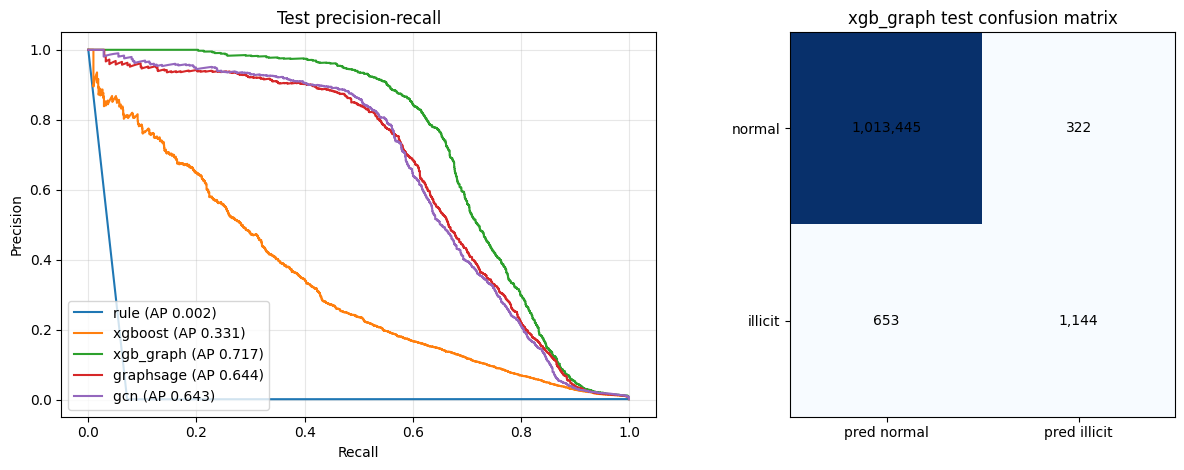

In [53]:
# best model by validation PR-AUC, the rule engine does not count
BEST_NAME = max([k for k in RESULTS if k != "rule"], key=lambda k: RESULTS[k]["val_pr_auc"])
print("best model:", BEST_NAME)

yt = Y[IDX[2]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

for name, (_, s_test) in SCORES.items():
    p, r_, _ = precision_recall_curve(yt, s_test)
    ax[0].plot(r_, p, label=f"{name} (AP {RESULTS[name]['test_pr_auc']:.3f})")
ax[0].set_xlabel("Recall")
ax[0].set_ylabel("Precision")
ax[0].set_title("Test precision-recall")
ax[0].legend()
ax[0].grid(alpha=0.3)

cm = confusion_matrix(yt, SCORES[BEST_NAME][1] >= THRESH[BEST_NAME]["f1"])
ax[1].imshow(cm, cmap="Blues")
ax[1].set_title(f"{BEST_NAME} test confusion matrix")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, f"{v:,}", ha="center", va="center")
ax[1].set_xticks([0, 1], ["pred normal", "pred illicit"])
ax[1].set_yticks([0, 1], ["normal", "illicit"])

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/model_comparison.png", dpi=110)
plt.show()

In [54]:
best = RESULTS[BEST_NAME]
checks = [
    ("accuracy >= 80% (not meaningful, flagging nothing gives 99.9%)", best["f1op_accuracy"]),
    ("balanced accuracy >= 80% at the best-F1 threshold", best["f1op_balanced_accuracy"]),
    ("balanced accuracy >= 80% at the 80% recall threshold", best["r80op_balanced_accuracy"]),
    ("ROC-AUC >= 0.80", best["test_roc_auc"]),
    ("recall >= 80% at the 80% recall threshold", best["r80op_recall"]),
    ("precision >= 80% at the best-F1 threshold", best["f1op_precision"]),
    ("recall >= 80% at the best-F1 threshold", best["f1op_recall"]),
    ("F1 >= 80% at the best-F1 threshold", best["f1op_f1"]),
]

print("targets on the test period, model:", BEST_NAME)
for label, value in checks:
    print(f"{'PASS' if value >= 0.8 else 'FAIL'}  {value:6.3f}  {label}")

print(f"\nat 80% recall the model flags {100 * best['r80op_alert_rate']:.2f}% of test transactions "
      f"({int(best['r80op_alerts']):,} alerts) with {100 * best['r80op_precision']:.1f}% precision")

targets on the test period, model: xgb_graph
PASS   0.999  accuracy >= 80% (not meaningful, flagging nothing gives 99.9%)
PASS   0.818  balanced accuracy >= 80% at the best-F1 threshold
PASS   0.929  balanced accuracy >= 80% at the 80% recall threshold
PASS   0.990  ROC-AUC >= 0.80
PASS   0.872  recall >= 80% at the 80% recall threshold
FAIL   0.780  precision >= 80% at the best-F1 threshold
FAIL   0.637  recall >= 80% at the best-F1 threshold
FAIL   0.701  F1 >= 80% at the best-F1 threshold

at 80% recall the model flags 1.56% of test transactions (15,856 alerts) with 9.9% precision


### Ring level detection

Edge metrics hide one question: was the ring caught? A ring counts as detected when at least half of its transactions are flagged, and as touched when at least one is. Only rings with most of their transactions in the test period are included.

In [55]:
def ring_report(name, which="f1"):
    thr = THRESH[name][which]
    flag = np.zeros(n, dtype=bool)
    flag[IDX[2]] = SCORES[name][1] >= thr

    g = pd.DataFrame({"pid": df.pattern_id.values, "pt": df.ptype.values, "flag": flag, "test": SPL == 2})
    g = g[g.pid >= 0]

    rings = g.groupby("pid").agg(pt=("pt", "first"), edges=("flag", "size"), test_share=("test", "mean"),
                                 flagged=("flag", "mean"), any_flag=("flag", "max"))
    rings = rings[rings.test_share >= 0.5]
    rings["detected"] = rings.flagged >= 0.5

    out = rings.groupby("pt").agg(rings=("edges", "size"), detected=("detected", "mean"), touched=("any_flag", "mean"))
    out.index = [PTYPES[i] for i in out.index]
    out.loc["ALL"] = [len(rings), rings.detected.mean(), rings.any_flag.mean()]
    return out.round(3)

In [56]:
for name in ("xgboost", "xgb_graph", "gcn", "graphsage"):
    if name in RESULTS:
        print(f"--- {name}, best-F1 threshold ---")
        print(ring_report(name, "f1"))

--- xgboost, best-F1 threshold ---
                rings  detected  touched
BIPARTITE        18.0     0.278    0.611
CYCLE            16.0     0.438    0.812
FAN-IN           18.0     0.389    0.944
FAN-OUT          16.0     0.375    0.938
GATHER-SCATTER   26.0     0.346    0.885
RANDOM           15.0     0.200    0.600
SCATTER-GATHER   20.0     0.350    0.850
STACK            14.0     0.429    0.786
ALL             143.0     0.350    0.811
--- xgb_graph, best-F1 threshold ---
                rings  detected  touched
BIPARTITE        18.0     0.833    1.000
CYCLE            16.0     0.562    0.938
FAN-IN           18.0     0.944    1.000
FAN-OUT          16.0     0.938    1.000
GATHER-SCATTER   26.0     0.962    1.000
RANDOM           15.0     0.933    1.000
SCATTER-GATHER   20.0     1.000    1.000
STACK            14.0     0.857    1.000
ALL             143.0     0.888    0.993
--- gcn, best-F1 threshold ---
                rings  detected  touched
BIPARTITE        18.0     0.333    0

In [57]:
print(f"--- {BEST_NAME}, 80% recall threshold ---")
print(ring_report(BEST_NAME, "r80"))

--- xgb_graph, 80% recall threshold ---
                rings  detected  touched
BIPARTITE        18.0     1.000      1.0
CYCLE            16.0     0.938      1.0
FAN-IN           18.0     1.000      1.0
FAN-OUT          16.0     1.000      1.0
GATHER-SCATTER   26.0     1.000      1.0
RANDOM           15.0     1.000      1.0
SCATTER-GATHER   20.0     1.000      1.0
STACK            14.0     1.000      1.0
ALL             143.0     0.993      1.0


## 11. From flagged transactions to cases

Flagged test edges plus nearby high scoring context edges (top 0.5% of test scores) are merged into connected components. A component with at least one flagged edge becomes a case. A rule based tagger then names the structure of each case.

The ground truth ring types are only used to measure how good the tags are. They never go into the case text.

In [58]:
PIPE_MODEL = BEST_NAME
flag_thr = THRESH[PIPE_MODEL]["f1"]
test_idx = IDX[2]
test_scores = SCORES[PIPE_MODEL][1]

# also keep the top scoring test edges so a case has some context around the flagged ones
ctx_thr = min(flag_thr, float(np.quantile(test_scores, 1 - CTX_TOP_FRAC)))
keep = test_scores >= ctx_thr
fl_idx = test_idx[keep]
fl_score = test_scores[keep]

print(f"model {PIPE_MODEL} | flagged (score >= {flag_thr:.3f}): {(test_scores >= flag_thr).sum():,}")
print(f"with context edges (score >= {ctx_thr:.3f}): {len(fl_idx):,} of {len(test_idx):,} test transactions")

model xgb_graph | flagged (score >= 0.790): 1,466
with context edges (score >= 0.424): 5,079 of 1,015,564 test transactions


In [59]:
def tag_pattern(G):
    # name the structure of a small directed graph
    if G.number_of_nodes() < 2:
        return "OTHER"

    try:
        cycle = nx.find_cycle(G)
        if len(set(u for u, _ in cycle)) >= 3:
            return "CYCLE"
    except nx.NetworkXNoCycle:
        pass

    indeg, outdeg = dict(G.in_degree()), dict(G.out_degree())
    sources = [v for v in G if indeg[v] == 0]
    sinks = [v for v in G if outdeg[v] == 0]
    middle = [v for v in G if indeg[v] > 0 and outdeg[v] > 0]

    if len(sources) == 1 and outdeg[sources[0]] >= 3 and not middle:
        return "FAN-OUT"
    if len(sinks) == 1 and indeg[sinks[0]] >= 3 and not middle:
        return "FAN-IN"
    if len(sources) == 1 and len(sinks) == 1 and len(middle) >= 2 and all(indeg[v] == 1 and outdeg[v] == 1 for v in middle):
        return "SCATTER-GATHER"

    hubs = [v for v in middle if indeg[v] >= 2 and outdeg[v] >= 2]
    if len(hubs) == 1 and len(middle) == 1:
        return "GATHER-SCATTER"
    if len(middle) == 0 and len(sources) >= 2 and len(sinks) >= 2:
        return "BIPARTITE"
    if len(middle) >= 2 and len(sources) >= 2 and len(sinks) >= 2:
        return "STACK"
    return "OTHER"

In [60]:
# sanity check on one small example of every structure
examples = {
    "FAN-OUT": [(0, 1), (0, 2), (0, 3)],
    "FAN-IN": [(1, 0), (2, 0), (3, 0)],
    "CYCLE": [(0, 1), (1, 2), (2, 0)],
    "SCATTER-GATHER": [(0, 1), (0, 2), (1, 3), (2, 3)],
    "GATHER-SCATTER": [(1, 0), (2, 0), (0, 3), (0, 4)],
    "BIPARTITE": [(0, 2), (0, 3), (1, 2), (1, 3)],
    "STACK": [(0, 2), (1, 3), (2, 4), (3, 5), (2, 5)],
}
for expected, edges in examples.items():
    assert tag_pattern(nx.DiGraph(edges)) == expected, expected
print("tagger works on all", len(examples), "example structures")

tagger works on all 7 example structures


In [61]:
# connected components over the flagged + context edges
src_nodes, dst_nodes = S[fl_idx], D[fl_idx]
uniq, inv2 = np.unique(np.concatenate([src_nodes, dst_nodes]), return_inverse=True)

adj = sp.coo_matrix((np.ones(len(fl_idx)), (inv2[:len(src_nodes)], inv2[len(src_nodes):])),
                    shape=(len(uniq), len(uniq)))
n_comp, labels = connected_components(adj, directed=False)
comp_of_edge = labels[inv2[:len(src_nodes)]]

# a component is a case only if it contains a flagged edge
n_flag = np.bincount(comp_of_edge, weights=(fl_score >= flag_thr).astype(float), minlength=n_comp)
print("components:", n_comp, "| cases:", int((n_flag > 0).sum()))

order_c = np.argsort(comp_of_edge, kind="stable")
bounds = np.searchsorted(comp_of_edge[order_c], np.arange(n_comp + 1))

components: 3531 | cases: 428


In [62]:
cases = []
case_gt = {}    # ground truth, only used for scoring

for c in np.where(n_flag > 0)[0]:
    rows = order_c[bounds[c]:bounds[c + 1]]
    eidx = fl_idx[rows]
    scores = fl_score[rows]
    sub = df.iloc[eidx]
    case_id = f"CASE-{len(cases) + 1:04d}"

    G = nx.DiGraph()
    G.add_edges_from(zip(sub.src.values.tolist(), sub.dst.values.tolist()))
    G_noloop = G.copy()
    G_noloop.remove_edges_from(list(nx.selfloop_edges(G_noloop)))
    tag = tag_pattern(G_noloop) if len(eidx) <= 400 else "OTHER"

    totals = sub.groupby("cur_p").amt_p.sum().round(2)

    # the report lists the highest scoring edges, in time order
    listed = sub.assign(score=scores).sort_values("score", ascending=False).head(MAX_CASE_EDGES_LISTED).sort_values("ts")
    if len(eidx) <= 400:
        nodes = list(G.nodes())
    else:
        nodes = sorted(set(listed.src.tolist()) | set(listed.dst.tolist()))

    edges = [dict(txn_id=int(r.Index), time=ts_str(r.ts),
                  from_account=acct_label(r.src), to_account=acct_label(r.dst),
                  amount=float(round(r.amt_p, 2)), currency=CUR_NAMES[int(r.cur_p)],
                  payment_format=FMT_NAMES[int(r.fmt)], risk_score=round(float(r.score), 4))
             for r in listed.itertuples()]

    cases.append(dict(
        case_id=case_id, pattern_tag=tag,
        n_accounts=int(G.number_of_nodes()), n_edges=int(len(eidx)), n_flagged=int((scores >= flag_thr).sum()),
        edges_listed=int(len(listed)),
        time_start=ts_str(sub.ts.min()), time_end=ts_str(sub.ts.max()),
        duration_hours=round((sub.ts.max() - sub.ts.min()) / 60, 1),
        max_score=round(float(scores.max()), 4), mean_score=round(float(scores.mean()), 4),
        totals_by_currency={CUR_NAMES[int(k)]: float(v) for k, v in totals.items() if v > 0},
        accounts=[acct_label(a) for a in nodes], edges=edges))

    gt = sub[sub.pattern_id >= 0]
    case_gt[case_id] = dict(
        precision=float((sub.y == 1).mean()),
        gt_type=PTYPES[int(gt.ptype.mode().iloc[0])] if len(gt) else None)

print("cases built:", len(cases))

cases built: 428


In [63]:
cd = pd.DataFrame([
    {**{k: c[k] for k in ("case_id", "pattern_tag", "n_accounts", "n_edges", "n_flagged", "duration_hours", "max_score")},
     "precision": case_gt[c["case_id"]]["precision"], "gt_type": case_gt[c["case_id"]]["gt_type"]}
    for c in cases])

print("mean share of illicit transactions inside a case: %.3f" % cd.precision.mean())
print("cases with >= 50%% illicit transactions: %d / %d" % ((cd.precision >= 0.5).sum(), len(cd)))

true_cases = cd[(cd.gt_type.notna()) & (cd.precision >= 0.5)]
if len(true_cases):
    print("pattern tag accuracy on true ring cases: %.3f (n=%d)" % ((true_cases.pattern_tag == true_cases.gt_type).mean(), len(true_cases)))
    print(pd.crosstab(true_cases.gt_type, true_cases.pattern_tag))

mean share of illicit transactions inside a case: 0.443
cases with >= 50% illicit transactions: 208 / 428
pattern tag accuracy on true ring cases: 0.201 (n=204)
pattern_tag     BIPARTITE  CYCLE  FAN-IN  FAN-OUT  GATHER-SCATTER  OTHER  SCATTER-GATHER  STACK
gt_type                                                                                        
BIPARTITE               0      0       0        0               0     37               0      0
CYCLE                   0      5       0        0               0      9               4      0
FAN-IN                  2      0       9        0               0      3               0      0
FAN-OUT                 2      0       0        8               0      4               0      0
GATHER-SCATTER          3      1       0        3              16      4               0      3
RANDOM                  0      0       0        0               0      7               7      0
SCATTER-GATHER          0      1       1        0               0     1

In [64]:
cd.sort_values("n_edges", ascending=False).head(8)

,case_id,pattern_tag,n_accounts,n_edges,n_flagged,duration_hours,max_score,precision,gt_type
136,CASE-0137,CYCLE,37,87,80,217.1,0.9966,0.919540,SCATTER-GATHER
24,CASE-0025,SCATTER-GATHER,18,38,36,90.9,0.9978,0.842105,SCATTER-GATHER
3,CASE-0004,STACK,28,34,26,109.3,0.9965,0.911765,SCATTER-GATHER
134,CASE-0135,OTHER,16,31,28,125.8,0.9946,0.806452,SCATTER-GATHER
56,CASE-0057,STACK,30,30,26,185.2,0.9986,0.900000,GATHER-SCATTER
49,CASE-0050,STACK,29,29,26,198.8,0.9970,0.931034,GATHER-SCATTER
44,CASE-0045,GATHER-SCATTER,29,29,28,150.8,0.9983,0.896552,GATHER-SCATTER
119,CASE-0120,OTHER,16,28,27,88.6,0.9984,0.928571,SCATTER-GATHER


In [65]:
# pick the cases for SAR drafting: high score and big enough to be interesting
cd["rank_score"] = cd.max_score * np.log1p(cd.n_edges)
pick_ids = cd[(cd.n_edges >= 3) & (cd.n_edges <= 400)].sort_values("rank_score", ascending=False).head(N_CASES_FOR_SAR).case_id.tolist()
CASES = {c["case_id"]: c for c in cases}
print("selected:", pick_ids)

selected: ['CASE-0137', 'CASE-0025', 'CASE-0004', 'CASE-0135', 'CASE-0057', 'CASE-0045', 'CASE-0050', 'CASE-0120', 'CASE-0061', 'CASE-0144', 'CASE-0138', 'CASE-0010']


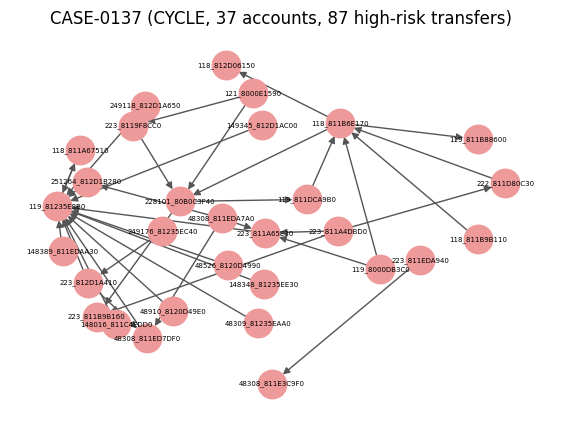

In [66]:
def draw_case(case, path=None):
    G = nx.DiGraph()
    for e in case["edges"]:
        G.add_edge(e["from_account"], e["to_account"])

    plt.figure(figsize=(7, 5))
    layout = nx.spring_layout(G, seed=3, k=0.9)
    nx.draw_networkx(G, layout, node_size=420, node_color="#EF9A9A", edge_color="#555",
                     font_size=5, arrows=True, arrowsize=10)
    plt.title(f"{case['case_id']} ({case['pattern_tag']}, {case['n_accounts']} accounts, {case['n_edges']} high-risk transfers)")
    plt.axis("off")
    if path:
        plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()


if pick_ids:
    draw_case(CASES[pick_ids[0]], f"{OUT_DIR}/case_example.png")

## 12. Drafting the SARs

Each case becomes a draft report with the usual sections: who (key accounts), what, when, where (banks and currencies), why it looks suspicious and how the money moved. The text comes from plain python templates filled with the case data, and the chronology table is built straight from the transactions. No external model or service is involved.

In [67]:
def money(x):
    return f"{x:,.2f}"


def case_facts(case):
    # how often each account shows up in the listed transfers
    deg = {}
    for e in case["edges"]:
        for acct in (e["from_account"], e["to_account"]):
            deg[acct] = deg.get(acct, 0) + 1

    key_accounts = [a for a, _ in sorted(deg.items(), key=lambda kv: -kv[1])[:6]]
    banks = sorted({a.split("_")[0] for a in case["accounts"]})
    return dict(
        key_accounts=key_accounts,
        n_banks=len(banks),
        formats=sorted({e["payment_format"] for e in case["edges"]}),
        total_value_by_currency={k: money(v) for k, v in case["totals_by_currency"].items()},
    )

In [68]:
STRUCT_TEXT = {
    "FAN-OUT": "funds leave one account and are spread across many recipient accounts",
    "FAN-IN": "funds from many accounts are collected into a single receiving account",
    "CYCLE": "funds travel through a chain of accounts and return towards the starting account",
    "SCATTER-GATHER": "funds are split from one account across several intermediaries and then gathered into one account",
    "GATHER-SCATTER": "funds from several accounts are gathered into a hub account and then redistributed",
    "BIPARTITE": "a group of sending accounts moves funds directly to a separate group of receiving accounts",
    "STACK": "funds pass through several layers of accounts before reaching final recipients",
    "OTHER": "funds move through a connected group of accounts in a pattern that the structure rules could not classify",
}


def write_narrative(case):
    v = case_facts(case)
    totals = "; ".join(f"{amount} {cur}" for cur, amount in v["total_value_by_currency"].items())
    ids = ", ".join(v["key_accounts"][:4])
    d0, d1 = case["time_start"][:10], case["time_end"][:10]

    summary = (
        f"Between {d0} and {d1}, {case['n_accounts']} accounts were involved in {case['n_edges']} transactions "
        f"that the monitoring model scored as high risk ({case['pattern_tag']} structure). Key accounts: {ids}. "
        f"These transactions total {totals}. The activity lasted {case['duration_hours']} hours. "
        f"The accounts are held at {v['n_banks']} bank(s) and payment formats seen are: {', '.join(v['formats'])}.")

    reasoning = (
        f"The high-risk transactions form a connected group where {STRUCT_TEXT[case['pattern_tag']]}. "
        f"The group contains {case['n_accounts']} accounts and {case['n_edges']} transactions, which is more complex than "
        f"ordinary customer behaviour. The transfers occur within {case['duration_hours']} hours, which suggests rapid movement of funds. "
        f"The model assigned a maximum risk score of {case['max_score']}. An investigator should review the source of funds for the "
        f"accounts {ids}, check customer profiles against the transaction volume, and look for further links to other accounts.")
    return summary, reasoning

### Grounding check

Every fact in the text has to be findable in the case data: account ids, two decimal amounts, dates, currencies, and the counts of accounts and transactions. Status is `PASS` or `FAIL` with the issues listed.

In [69]:
ACCT_RE = re.compile(r"\b\d{1,8}_[0-9A-Za-z]{8,10}\b")
AMOUNT_RE = re.compile(r"(?<![\d.])\d{1,3}(?:,\d{3})*\.\d{2}(?![\d])|(?<![\d.,])\d+\.\d{2}(?![\d])")
DATE_RE = re.compile(r"\b\d{4}-\d{2}-\d{2}\b")
ALL_CURRENCIES = set(CUR_NAMES)


def verify_narrative(case, text):
    issues = []

    ok_accts = set(case["accounts"])
    ok_amts = {round(e["amount"], 2) for e in case["edges"]} | {round(v, 2) for v in case["totals_by_currency"].values()}
    ok_dates = {e["time"][:10] for e in case["edges"]} | {case["time_start"][:10], case["time_end"][:10]}

    for a in ACCT_RE.findall(text):
        if a not in ok_accts:
            issues.append(f"account not in case: {a}")

    for a in AMOUNT_RE.findall(text):
        v = round(float(a.replace(",", "")), 2)
        # the max score and the duration are also written with two decimals sometimes
        if v not in ok_amts and v != round(case["max_score"], 2) and v != round(case["duration_hours"], 2):
            issues.append(f"amount not in case: {a}")

    for d in DATE_RE.findall(text):
        if d not in ok_dates:
            issues.append(f"date not in case: {d}")

    used_cur = {c for c in ALL_CURRENCIES if re.search(r"\b" + re.escape(c) + r"\b", text)}
    for c in used_cur - set(case["totals_by_currency"]):
        issues.append(f"currency not in case: {c}")

    for m in re.finditer(r"(\d+)\s+(?:distinct\s+|different\s+)?accounts", text):
        if int(m.group(1)) != case["n_accounts"]:
            issues.append(f"account count {m.group(1)} != {case['n_accounts']}")

    for m in re.finditer(r"(\d+)\s+(?:flagged\s+|suspicious\s+)?(?:transactions|transfers)", text):
        if int(m.group(1)) != case["n_edges"]:
            issues.append(f"transaction count {m.group(1)} != {case['n_edges']}")

    return dict(status="PASS" if not issues else "FAIL", issues=sorted(set(issues)))

In [70]:
# the verifier should pass a clean draft and catch a tampered one
c0 = CASES[pick_ids[0]]
s0, r0 = write_narrative(c0)
print("clean draft:", verify_narrative(c0, s0 + r0)["status"])

bad = s0.replace(c0["accounts"][0], "999_ABCDEF123") + " The accounts moved 123,456.78 on 2031-01-01 across 999 accounts."
print("tampered draft:", verify_narrative(c0, bad))

clean draft: PASS
tampered draft: {'status': 'FAIL', 'issues': ['account count 999 != 37', 'amount not in case: 123,456.78', 'date not in case: 2031-01-01']}


## 13. Assemble and export

In [71]:
def assemble_sar(case, summary, reasoning, grounding):
    rows = "\n".join(
        f"| {e['time']} | {e['from_account']} | {e['to_account']} | {money(e['amount'])} {e['currency']} | {e['payment_format']} |"
        for e in case["edges"])

    note = ""
    if case["edges_listed"] != case["n_edges"]:
        note = f"\n*Showing the {case['edges_listed']} highest-risk of {case['n_edges']} high-risk transactions in chronological order.*\n"

    totals = "; ".join(f"{money(v)} {k}" for k, v in case["totals_by_currency"].items())
    issues = "" if not grounding["issues"] else " (" + "; ".join(grounding["issues"]) + ")"

    return (
        f"# Suspicious Activity Report (DRAFT) - {case['case_id']}\n\n"
        f"**Pattern structure:** {case['pattern_tag']} | **Accounts:** {case['n_accounts']} | **Transactions:** {case['n_edges']} | "
        f"**Period:** {case['time_start']} to {case['time_end']} | **Total value:** {totals}\n\n"
        f"## 1. Executive Summary\n{summary}\n\n"
        f"## 2. Chronology of Transactions\n\n"
        f"| Time | From account | To account | Amount | Format |\n|---|---|---|---|---|\n{rows}\n{note}\n"
        f"## 3. Suspicious Pattern Reasoning\n{reasoning}\n\n---\n"
        f"*Generated by a rule-based writer. Grounding check: **{grounding['status']}**{issues}. "
        f"This is an automatically generated draft and must be reviewed and approved by a compliance officer before use.*\n")

In [72]:
SARS = []

for cid in pick_ids:
    case = CASES[cid]
    summary, reasoning = write_narrative(case)
    grounding = verify_narrative(case, summary + "\n" + reasoning)
    md_text = assemble_sar(case, summary, reasoning, grounding)

    SARS.append(dict(case_id=cid, grounding_status=grounding["status"], issues=grounding["issues"],
                     markdown=md_text, summary=summary, reasoning=reasoning, grounding=grounding,
                     truth_precision=case_gt[cid]["precision"], truth_type=case_gt[cid]["gt_type"]))

    with open(f"{OUT_DIR}/sar_{cid}.md", "w") as f:
        f.write(md_text)

sar_df = pd.DataFrame(SARS)[["case_id", "grounding_status", "truth_precision", "truth_type"]]
print(f"drafted {len(SARS)} SARs")
print(sar_df.to_string(index=False))
print("grounding pass rate: %.1f%%" % (100 * (sar_df.grounding_status == "PASS").mean()))

drafted 12 SARs
  case_id grounding_status  truth_precision     truth_type
CASE-0137             PASS         0.919540 SCATTER-GATHER
CASE-0025             PASS         0.842105 SCATTER-GATHER
CASE-0004             PASS         0.911765 SCATTER-GATHER
CASE-0135             PASS         0.806452 SCATTER-GATHER
CASE-0057             PASS         0.900000 GATHER-SCATTER
CASE-0045             PASS         0.896552 GATHER-SCATTER
CASE-0050             PASS         0.931034 GATHER-SCATTER
CASE-0120             PASS         0.928571 SCATTER-GATHER
CASE-0061             PASS         0.928571 GATHER-SCATTER
CASE-0144             PASS         0.962963 GATHER-SCATTER
CASE-0138             PASS         1.000000 GATHER-SCATTER
CASE-0010             PASS         0.807692 SCATTER-GATHER
grounding pass rate: 100.0%


In [73]:
# look at one of them
print(SARS[0]["markdown"][:2500])

# Suspicious Activity Report (DRAFT) - CASE-0137

**Pattern structure:** CYCLE | **Accounts:** 37 | **Transactions:** 87 | **Period:** 2022-09-08 16:19:00 to 2022-09-17 17:23:00 | **Total value:** 19,201.33 Australian Dollar; 162,304,713.45 Saudi Riyal

## 1. Executive Summary
Between 2022-09-08 and 2022-09-17, 37 accounts were involved in 87 transactions that the monitoring model scored as high risk (CYCLE structure). Key accounts: 119_81235E8B0, 118_811B6E170, 223_812D1A410, 228101_80B0C3F40. These transactions total 19,201.33 Australian Dollar; 162,304,713.45 Saudi Riyal. The activity lasted 217.1 hours. The accounts are held at 17 bank(s) and payment formats seen are: ACH.

## 2. Chronology of Transactions

| Time | From account | To account | Amount | Format |
|---|---|---|---|---|
| 2022-09-08 16:19:00 | 121_8000E1590 | 223_8119F8CC0 | 51,203.66 Saudi Riyal | ACH |
| 2022-09-08 17:07:00 | 223_811A4DBD0 | 223_811B9B160 | 5,212.74 Saudi Riyal | ACH |
| 2022-09-09 01:01:00 | 148389_

In [74]:
# pdf versions of the first three
try:
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import getSampleStyleSheet
    from reportlab.lib import colors
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
    HAVE_PDF = True
except Exception:
    HAVE_PDF = False

from xml.sax.saxutils import escape


def export_pdf(case, summary, reasoning, grounding, path):
    styles = getSampleStyleSheet()
    doc = SimpleDocTemplate(path, pagesize=A4, leftMargin=36, rightMargin=36, topMargin=36, bottomMargin=36)
    totals = "; ".join(f"{money(v)} {k}" for k, v in case["totals_by_currency"].items())

    header = (f"Pattern: {case['pattern_tag']} | Accounts: {case['n_accounts']} | Transactions: {case['n_edges']} | "
              f"Period: {case['time_start']} to {case['time_end']} | Total: {totals}")

    table_data = [["Time", "From account", "To account", "Amount", "Format"]]
    for e in case["edges"]:
        table_data.append([e["time"], e["from_account"], e["to_account"], f"{money(e['amount'])} {e['currency']}", e["payment_format"]])

    table = Table(table_data, repeatRows=1, colWidths=[78, 105, 105, 120, 60])
    table.setStyle(TableStyle([
        ("FONTSIZE", (0, 0), (-1, -1), 6.5),
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#D9E2F3")),
        ("GRID", (0, 0), (-1, -1), 0.25, colors.grey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ]))

    story = [
        Paragraph(f"Suspicious Activity Report (DRAFT) - {case['case_id']}", styles["Title"]),
        Paragraph(escape(header), styles["BodyText"]),
        Spacer(1, 8),
        Paragraph("1. Executive Summary", styles["Heading2"]),
        Paragraph(escape(summary), styles["BodyText"]),
        Paragraph("2. Chronology of Transactions", styles["Heading2"]),
        table,
        Paragraph("3. Suspicious Pattern Reasoning", styles["Heading2"]),
        Paragraph(escape(reasoning), styles["BodyText"]),
        Spacer(1, 10),
        Paragraph(escape(f"Rule-based draft. Grounding check: {grounding['status']}. For human review, not a filed report."), styles["Italic"]),
    ]
    doc.build(story)


if HAVE_PDF:
    for sar in SARS[:3]:
        export_pdf(CASES[sar["case_id"]], sar["summary"], sar["reasoning"], sar["grounding"], f"{OUT_DIR}/sar_{sar['case_id']}.pdf")
else:
    print("reportlab is missing, skipping pdf export (pip install reportlab)")

print("pdfs:", [f for f in os.listdir(OUT_DIR) if f.endswith(".pdf")])

pdfs: ['sar_CASE-0137.pdf', 'sar_CASE-0025.pdf', 'sar_CASE-0004.pdf']


## 14. Save the models and the deployment bundle

Writes everything the `aml_service` package needs into `outputs/models/` and checks that the saved files reproduce the in-memory scores. The served model is the two stage XGBoost (`xgb_graph`), the best model on validation. GraphSAGE and GCN checkpoints are saved too, but they need the full transaction graph at inference, so the service does not serve them.

In [75]:
MODEL_DIR = f"{OUT_DIR}/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# stage 1 scores every transaction on its own, stage 2 adds the neighbour scores
xgb_model.save_model(f"{MODEL_DIR}/xgboost_aml.json")
xgb_graph.save_model(f"{MODEL_DIR}/xgboost_graph_stage2_aml.json")

In [76]:
# everything the service needs to rebuild the features and apply the thresholds
prep = dict(
    bundle_version=2,
    best_model=BEST_NAME,
    thresholds={k: {a: float(b) for a, b in v.items()} for k, v in THRESH.items()},
    edge_feature_names=E_NAMES, edge_mu=[float(x) for x in E_MU], edge_sd=[float(x) for x in E_SD],
    neighbour_feature_names=NB_NAMES, neighbour_high_cut=float(NB_HIGH_CUT),
    format_names=FMT_NAMES, currency_names=CUR_NAMES,
    t0="2022-09-01", big=30000.0, windows_minutes=[60, 1440, None],
    rule=dict(amount=float(A_best), k=int(K_best)),
    split_minutes=[float(q1), float(q2)],
    versions=dict(xgboost=xgb.__version__, numpy=np.__version__, pandas=pd.__version__),
)
with open(f"{MODEL_DIR}/preprocessing_and_thresholds.json", "w") as f:
    json.dump(prep, f, indent=1)

with open(f"{OUT_DIR}/cases.json", "w") as f:
    json.dump(CASES, f, indent=1)

sar_index = [{k: v for k, v in s.items() if k not in ("markdown", "grounding")} for s in SARS]
with open(f"{OUT_DIR}/sar_index.json", "w") as f:
    json.dump(sar_index, f, indent=1)

# the saved xgboost files must give the same scores as the models in memory
chk = IDX[2][:50_000]
m1 = xgb.XGBClassifier()
m1.load_model(f"{MODEL_DIR}/xgboost_aml.json")
assert np.allclose(xgb_predict(m1, chk), SCORES["xgboost"][1][:50_000], atol=1e-5)

m2 = xgb.XGBClassifier()
m2.load_model(f"{MODEL_DIR}/xgboost_graph_stage2_aml.json")
assert np.allclose(stack_predict(m2, chk), SCORES["xgb_graph"][1][:50_000], atol=1e-5)
print("xgboost reload check passed")

In [77]:
# GNN checkpoints (not served, kept for the report and for batch experiments)
def save_gnn(model, name):
    torch.save(dict(
        state_dict={k: v.cpu() for k, v in model.state_dict().items()},
        node_in=int(node_in), edge_in=int(edge_in), hidden=HIDDEN, layers=GNN_LAYERS,
        thr={k: float(v) for k, v in THRESH[name].items()},
        node_mu=torch.from_numpy(nf_mu), node_sd=torch.from_numpy(nf_sd)),
        f"{MODEL_DIR}/{name}_aml.pt")


save_gnn(sage, "graphsage")
if gcn is not None:
    save_gnn(gcn, "gcn")

ck = torch.load(f"{MODEL_DIR}/graphsage_aml.pt", weights_only=True)
s2 = SAGEEdgeNet(ck["node_in"], ck["edge_in"], ck["hidden"], ck["layers"]).to(DEVICE)
s2.load_state_dict(ck["state_dict"])
assert np.allclose(predict(s2, get_view("test"), chk), SCORES["graphsage"][1][:50_000], atol=1e-4)
print("graphsage reload check passed")

reload check passed


In [78]:
b = RESULTS[BEST_NAME]
table_rows = "\n".join(
    f"| {k} | {v['f1op_accuracy']:.4f} | {v['f1op_balanced_accuracy']:.3f} | {v['test_roc_auc']:.3f} | "
    f"{v['test_pr_auc']:.3f} | {v['f1op_precision']:.3f} | {v['f1op_recall']:.3f} | {v['f1op_f1']:.3f} |"
    for k, v in RESULTS.items())

card = f'''# Model card: GraphSAR AML models

Data: IBM AML HI-Small (synthetic), {n:,} transactions, {N_NODES:,} accounts, illicit rate {100 * df.y.mean():.3f}%. Sample days: {SAMPLE_DAYS or 'all'}.
Time split 60/20/20. Thresholds are picked on validation and applied to the later test period.
Best model on validation PR-AUC: **{BEST_NAME}**.

| Model | Accuracy | Balanced acc | ROC-AUC | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|
{table_rows}

At the 80% recall threshold ({BEST_NAME}): recall {b['r80op_recall']:.3f}, precision {b['r80op_precision']:.3f}, alerts {b['r80op_alert_rate'] * 100:.2f}% of transactions.

Intended use: academic prototype and decision support. Not validated on real bank data. Every SAR draft needs human review.
'''

with open(f"{OUT_DIR}/model_card.md", "w") as f:
    f.write(card)
print(card)

# Model card: GraphSAR AML models

Data: IBM AML HI-Small (synthetic), 5,078,345 transactions, 515,088 accounts, illicit rate 0.102%. Sample days: all.
Time split 60/20/20. Thresholds are picked on validation and applied to the later test period.
Best model on validation PR-AUC: **xgb_graph**.

| Model | Accuracy | Balanced acc | ROC-AUC | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|
| rule | 0.9023 | 0.488 | 0.488 | 0.002 | 0.001 | 0.072 | 0.003 |
| xgboost | 0.9980 | 0.669 | 0.983 | 0.331 | 0.416 | 0.338 | 0.373 |
| xgb_graph | 0.9990 | 0.818 | 0.990 | 0.717 | 0.780 | 0.637 | 0.701 |
| graphsage | 0.9989 | 0.779 | 0.988 | 0.644 | 0.771 | 0.558 | 0.647 |
| gcn | 0.9989 | 0.783 | 0.988 | 0.643 | 0.757 | 0.565 | 0.647 |

At the 80% recall threshold (xgb_graph): recall 0.872, precision 0.099, alerts 1.56% of transactions.

Intended use: academic prototype and decision support. Not validated on real bank data. Every SAR draft needs human review.



In [79]:
print(sorted(os.listdir(OUT_DIR)))
print(sorted(os.listdir(MODEL_DIR)))

['case_example.png', 'cases.json', 'eda.png', 'metrics_full.csv', 'metrics_headline.csv', 'model_card.md', 'model_comparison.png', 'models', 'sar_CASE-0004.md', 'sar_CASE-0004.pdf', 'sar_CASE-0010.md', 'sar_CASE-0025.md', 'sar_CASE-0025.pdf', 'sar_CASE-0045.md', 'sar_CASE-0050.md', 'sar_CASE-0057.md', 'sar_CASE-0061.md', 'sar_CASE-0120.md', 'sar_CASE-0135.md', 'sar_CASE-0137.md', 'sar_CASE-0137.pdf', 'sar_CASE-0138.md', 'sar_CASE-0144.md', 'sar_index.json']
['gcn_aml.pt', 'graphsage_aml.pt', 'preprocessing_and_thresholds.json', 'xgboost_aml.json', 'xgboost_graph_stage2_aml.json']


### Optional: end to end check of the service code

Runs the raw csv through `aml_service` (`aml_features.py` + `scorer.py`) and compares with the scores above. It reads all 5M rows again, so it is off by default. Upload the `aml_service` folder next to the notebook (on Kaggle: add it as a dataset and point `SERVICE_DIR` at it) and set the flag to `True`.

In [ ]:
RUN_SERVICE_PARITY = False
SERVICE_DIR = "aml_service"

if RUN_SERVICE_PARITY:
    sys.path.insert(0, SERVICE_DIR)
    import aml_features as af
    from scorer import AMLScorer

    raw = af.load_csv(TRANS_PATH)
    got = AMLScorer(MODEL_DIR).score(raw)

    # the notebook works on time sorted rows, the service returns the input order
    order = np.argsort(np.asarray(af._parse_time(raw["timestamp"])), kind="stable")
    got = got.iloc[order].reset_index(drop=True)

    diff = np.abs(got.risk_score.values[IDX[2]] - SCORES["xgb_graph"][1])
    agree = (got.flag.values[IDX[2]] == (SCORES["xgb_graph"][1] >= THRESH["xgb_graph"]["f1"])).mean()
    print(f"max score diff {diff.max():.2e}, 99.9th pct {np.quantile(diff, 0.999):.2e}, flag agreement {agree:.5f}")
    del raw, got
    trim()

In [ ]:
# one zip with the models to download / upload
import shutil
shutil.make_archive(f"{OUT_DIR}/aml_models", "zip", MODEL_DIR)
print(sorted(os.listdir(MODEL_DIR)))
print("zip:", f"{OUT_DIR}/aml_models.zip", f"{os.path.getsize(OUT_DIR + '/aml_models.zip') / 1e6:.1f} MB")